# Retail Sales Data Analysis & EDA

**Internship:** Oasis Infobyte – AICTE Data Analytics Internship  
**Task:** Level 1 – Task 1  
**Name:** Prajwal Poojary

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("retail_sales_dataset.csv")

In [3]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
df.shape

(1000, 9)

In [5]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')

In [6]:
 df.dtypes

Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

In [7]:
 df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [10]:
df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].mode()

,Age,Quantity,Price per Unit,Total Amount
0,43,4.0,50.0,50.0
1,64,NaN,NaN,NaN


In [11]:
df['Date'] = pd.to_datetime(df['Date'])

In [12]:
df.dtypes

Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

In [13]:
df['Date'].min(), df['Date'].max()

(Timestamp('2023-01-01 00:00:00'), Timestamp('2024-01-01 00:00:00'))

In [14]:
monthly_sales = df.groupby(df['Date'].dt.to_period('M'))['Total Amount'].sum()

In [15]:
monthly_sales

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

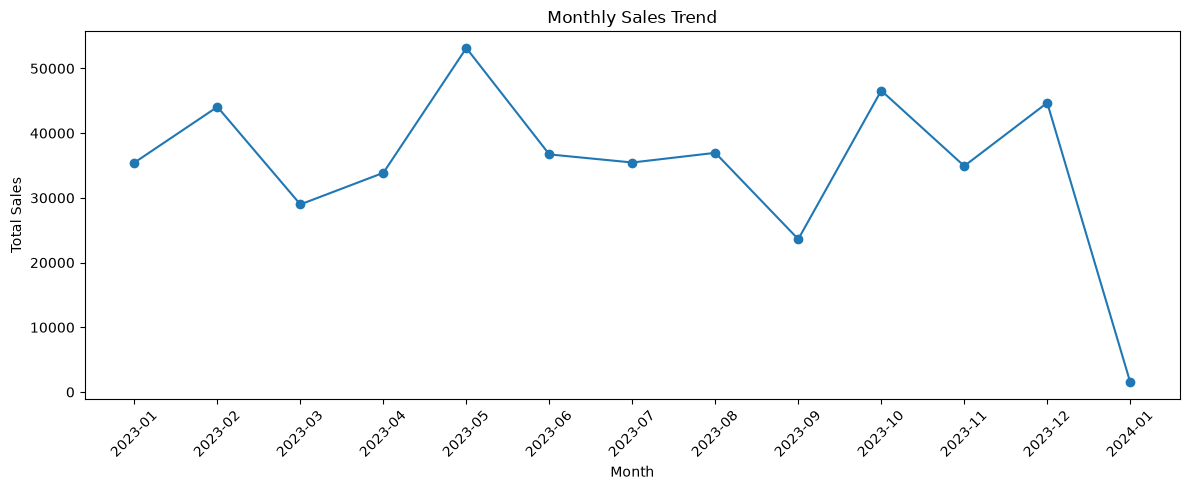

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation – Monthly Sales Trend

- Sales fluctuated considerably throughout 2023.
- May 2023 recorded the highest monthly sales at 53,150.
- September 2023 recorded the lowest monthly sales at 23,620.
- Sales increased again in October and December after lower sales in September.
- January 2024 shows only 1,530 in sales, which may represent partial-month data and should not be directly compared with the full months of 2023.

In [17]:
quarterly_sales = df.groupby(df['Date'].dt.to_period('Q'))['Total Amount'].sum()

In [18]:
quarterly_sales

Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64

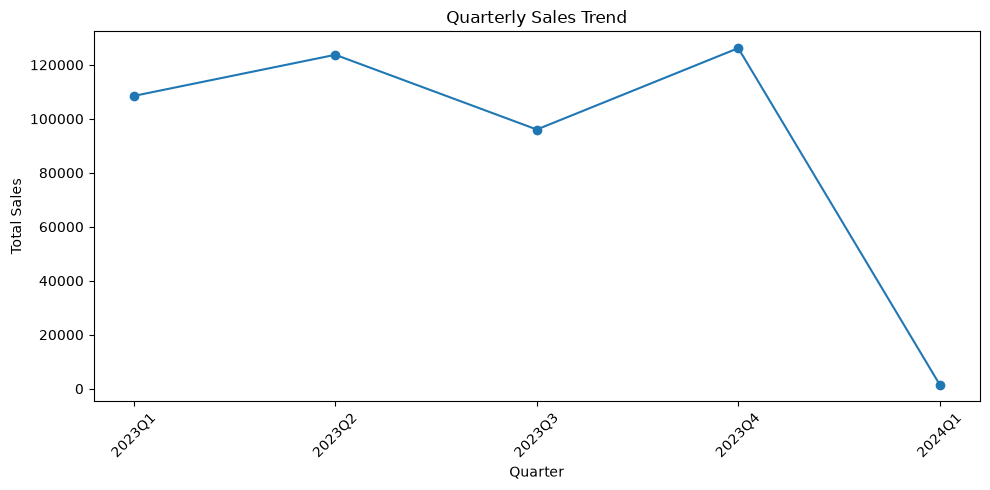

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(quarterly_sales.index.astype(str), quarterly_sales.values, marker='o')

plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation – Quarterly Sales Trend

- Q4 2023 recorded the highest quarterly sales at 126,190.
- Q2 2023 recorded the second-highest quarterly sales at 123,735.
- Q3 2023 recorded the lowest sales among the complete quarters of 2023 at 96,045.
- Sales increased from Q3 to Q4, indicating stronger performance toward the end of 2023.
- Q1 2024 contains only 1,530 in sales and appears to represent partial data, so it should not be compared directly with the complete quarters of 2023.

In [20]:
age_bins = [17, 25, 35, 45, 55, 64]
age_labels = ['18-25', '26-35', '36-45', '46-55', '56-64']

df['Age Group'] = pd.cut(
    df['Age'],
    bins=age_bins,
    labels=age_labels
)

In [21]:
df['Age Group'].value_counts().sort_index()

Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56-64    195
Name: count, dtype: int64

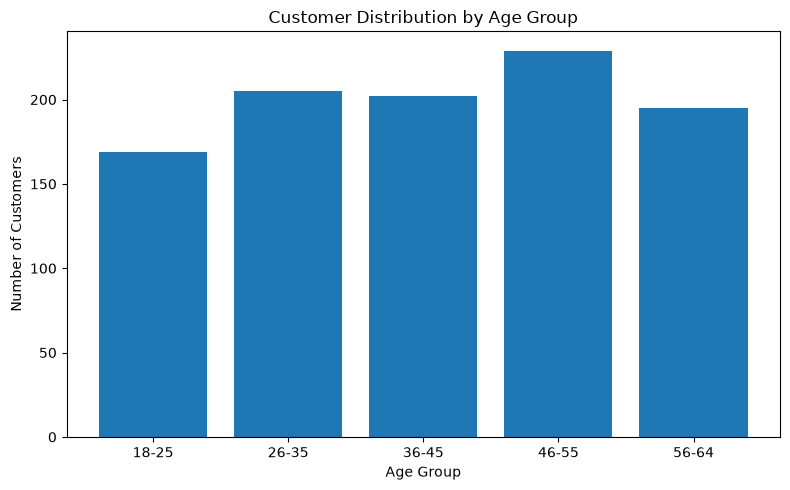

In [22]:
age_counts = df['Age Group'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(age_counts.index.astype(str), age_counts.values)

plt.title('Customer Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

### Observation – Customer Age Groups

- The 46–55 age group has the highest number of customers with 229 records.
- The 18–25 age group has the lowest representation with 169 customers.
- The 26–35 and 36–45 groups have similar customer counts, with 205 and 202 respectively.
- Overall, the customer base is fairly distributed across the different age groups, with a slightly higher representation among customers aged 46–55.

In [23]:
gender_counts = df['Gender'].value_counts()
gender_counts

Gender
Female    510
Male      490
Name: count, dtype: int64

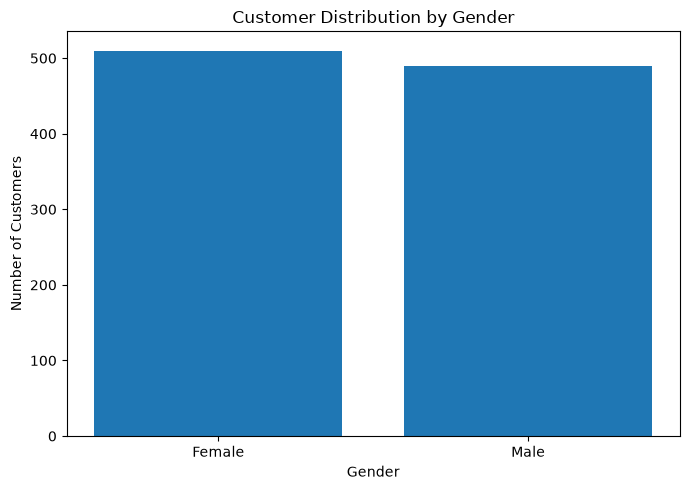

In [24]:
plt.figure(figsize=(7, 5))
plt.bar(gender_counts.index, gender_counts.values)

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

### Observation – Gender Distribution

- Female customers account for 510 records, while male customers account for 490 records.
- The distribution is nearly balanced, with female customers representing a slightly larger share.
- This indicates that the dataset does not have a strong gender imbalance in its customer base.

In [25]:
df['Product Category'].value_counts()

Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64

In [26]:
category_sales = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)

category_sales

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

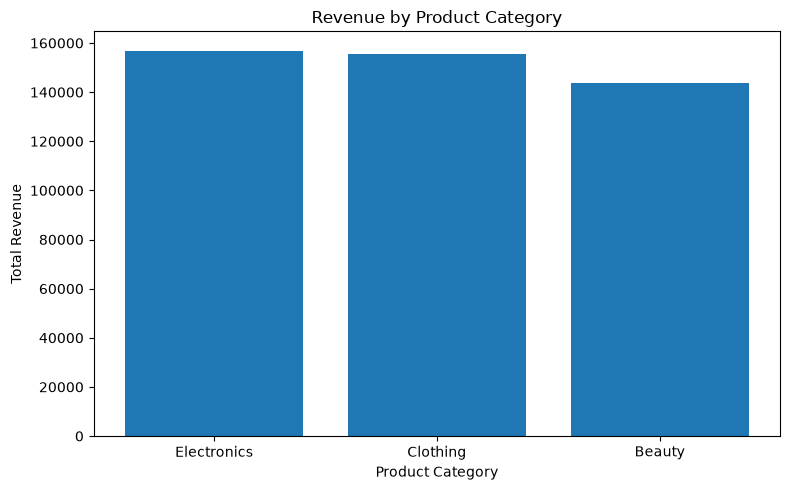

In [27]:
plt.figure(figsize=(8, 5))
plt.bar(category_sales.index, category_sales.values)

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.tight_layout()
plt.show()

### Observation – Revenue by Product Category

- Electronics generated the highest revenue at 156,905.
- Clothing generated 155,580, which is very close to Electronics.
- Beauty generated the lowest revenue among the three categories at 143,515.
- The revenue distribution is relatively balanced across the three product categories.
- The dataset contains Product Category but does not contain individual Product Name information. Therefore, a true Top 10 best-selling product analysis cannot be performed without introducing unsupported data. Category-level analysis is used instead.

In [2]:
import pandas as pd

df = pd.read_csv("retail_sales_dataset.csv")

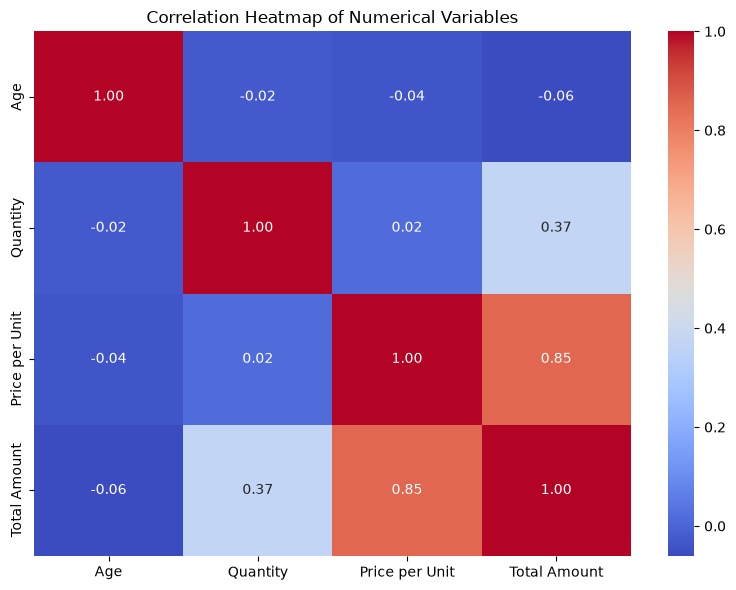

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation = df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

### Observation – Correlation Heatmap

- Price per Unit and Total Amount show a strong positive correlation of 0.85, indicating that higher-priced products generally contribute to higher transaction values.
- Quantity and Total Amount show a moderate positive correlation of 0.37, suggesting that purchasing more units tends to increase the total transaction amount.
- Age has a very weak relationship with Total Amount, with a correlation of -0.06.
- Age also shows very weak relationships with Quantity and Price per Unit.
- Overall, transaction value is more strongly associated with product price than with customer age.

In [7]:
age_bins = [17, 25, 35, 45, 55, 64]
age_labels = ['18-25', '26-35', '36-45', '46-55', '56-64']

df['Age Group'] = pd.cut(
    df['Age'],
    bins=age_bins,
    labels=age_labels
)

In [8]:
age_group_avg_spend = df.groupby('Age Group', observed=True)['Total Amount'].mean()

age_group_avg_spend

Age Group
18-25    500.295858
26-35    480.390244
36-45    454.801980
46-55    439.694323
56-64    412.358974
Name: Total Amount, dtype: float64

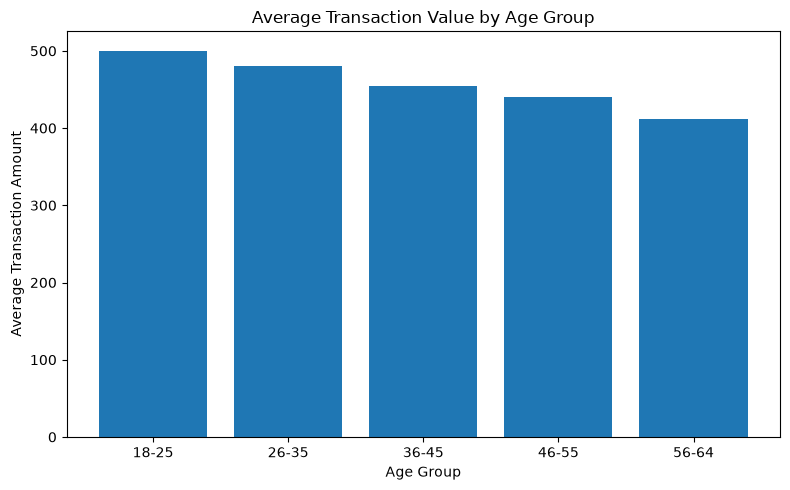

In [9]:
plt.figure(figsize=(8, 5))
plt.bar(age_group_avg_spend.index.astype(str), age_group_avg_spend.values)

plt.title('Average Transaction Value by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Transaction Amount')
plt.tight_layout()
plt.show()

### Observation – Average Transaction Value by Age Group

- Customers aged 18–25 have the highest average transaction value at approximately 500.30.
- Average transaction value gradually decreases across the age groups, from 500.30 for ages 18–25 to 412.36 for ages 56–64.
- The 26–35 age group has an average transaction value of approximately 480.39, while the 36–45 group averages 454.80.
- The 46–55 age group averages 439.69 per transaction.
- This suggests that younger customers in this dataset tend to make higher-value transactions than older customers.

In [10]:
numeric_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']

summary_stats = pd.DataFrame({
    'Mean': df[numeric_cols].mean(),
    'Median': df[numeric_cols].median(),
    'Mode': df[numeric_cols].mode().iloc[0],
    'Standard Deviation': df[numeric_cols].std()
})

summary_stats

,Mean,Median,Mode,Standard Deviation
Age,41.392,42.0,43.0,13.681430
Quantity,2.514,3.0,4.0,1.132734
Price per Unit,179.890,50.0,50.0,189.681356
Total Amount,456.000,135.0,50.0,559.997632


## Descriptive Statistics Summary

The table above summarizes the central tendency and variability of the main numerical variables in the retail sales dataset.

### Observation – Descriptive Statistics

- The average customer age is 41.39 years, with a median of 42 years.
- The average quantity purchased per transaction is 2.51 units, while the median is 3 units.
- The average price per unit is 179.89, with a median of 50, indicating variation in product pricing.
- The average transaction amount is 456, while the median is 135, indicating that some higher-value transactions increase the overall average.
- The relatively high standard deviation of Total Amount (559.997632) shows considerable variation in transaction values.

## Conclusion

The exploratory data analysis provides several insights into the sales performance and customer behavior in the retail dataset. Sales fluctuated throughout 2023, with May recording the highest monthly sales and Q4 recording the highest quarterly sales among the complete quarters. Electronics generated the highest category revenue, although Clothing performed very closely.

The customer base was relatively balanced across gender and age groups. An additional analysis of average transaction value showed that younger customers had higher average transaction values than older customers in this dataset. The correlation analysis also showed a strong positive relationship between Price per Unit and Total Amount, while Quantity had a moderate positive relationship with Total Amount.

Overall, the analysis indicates that product pricing, purchase quantity, customer age, and category performance can provide useful insights for improving retail sales strategies.

## Actionable Business Recommendations

1. **Focus on high-performing product categories:** Electronics generated the highest revenue, so the business can maintain strong inventory levels and promotional campaigns for Electronics while identifying ways to improve the performance of lower-revenue categories such as Beauty.

2. **Develop targeted strategies for younger customers:** Younger age groups showed higher average transaction values. The business could test targeted promotions, product bundles, and digital marketing campaigns aimed at these customer segments.

3. **Use pricing and quantity strategies:** Since Price per Unit has a strong positive relationship with Total Amount, the business should carefully evaluate pricing and promote higher-value products. Quantity also has a positive relationship with transaction value, so bundle offers and multi-unit promotions could encourage larger purchases.

4. **Plan inventory and promotions around sales trends:** Sales were strongest in May and Q4 2023. The business can use these seasonal patterns to prepare inventory and marketing campaigns ahead of historically stronger sales periods.

5. **Improve product-level data collection:** The dataset contains Product Category but does not include individual Product Name information. Recording product-level sales data would enable more detailed analysis such as identifying the top-selling products and evaluating individual product performance.